# **MÓDULO 18 - Pratique**
# Regressão Linear

Agora que aprendemos como aplicar a regressão linear simples e múltipla, colocaremos em prática os conceitos vistos na aula.

Temos aqui uma base de imóveis para alugar, precisamos desenvolver um modelo de regressão linear múltipla para conseguir prever o preço de imóveis dadas as variáveis independentes do nosso modelo.

**Atenção! Esse é seu primeiro modelo, caso tenha dificuldade conte com a ajuda da tutoria**

Você notará que alguns códigos já estão presentes para facilitar a construção de vocês.

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [2]:
df = pd.read_csv("ALUGUEL_MOD12.csv", delimiter=';')

df.head(10)

,Valor_Aluguel,Valor_Condominio,Metragem,N_Quartos,N_banheiros,N_Suites,N_Vagas
0,480,295,48,2,2,1,1
1,500,0,50,1,2,1,1
2,500,0,40,1,2,1,1
3,500,36,45,1,2,1,0
4,500,0,30,1,1,0,0
5,500,380,66,2,1,0,1
6,550,100,48,2,2,1,1
7,600,110,46,2,2,1,1
8,600,100,49,2,2,1,1
9,600,325,50,2,2,1,1


Legenda dos dados:

*   **Valor_Aluguel** : valor Total pago no aluguel

*   **Valor_Condominio** : Valor do Condomínio.

*   **Metragem** : Metragem do Apartamento.

*   **N_Quartos** : Número de Quartos do Imóvel.

*   **N_banheiros** : Número de banheiros.

*   **N_Suites** : Número de Suítes.

*   **N_Vagas** : Número de Vagas.

# 1 - Realize a primeira etapa de pré processamento dos dados.

A) Verifique os tipos de dados.


B) Verifique os dados faltantes, se houver dados faltantes faça a substituição ou remoção justificando sua escolha.

**A) Tipos de dados**

In [3]:
print('Linhas e colunas:', df.shape)
df.info()

Linhas e colunas: (7203, 7)
<class 'pandas.DataFrame'>
RangeIndex: 7203 entries, 0 to 7202
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Valor_Aluguel     7203 non-null   int64
 1   Valor_Condominio  7203 non-null   int64
 2   Metragem          7203 non-null   int64
 3   N_Quartos         7203 non-null   int64
 4   N_banheiros       7203 non-null   int64
 5   N_Suites          7203 non-null   int64
 6   N_Vagas           7203 non-null   int64
dtypes: int64(7)
memory usage: 394.0 KB


Todas as 7 colunas são do tipo `int64`, o que faz sentido para o significado de cada uma: valores em reais sem centavos, metragem em m² inteiros e contagens (quartos, banheiros, suítes e vagas). Não é preciso converter nenhum tipo.

**B) Dados faltantes**

In [4]:
df.isnull().sum()

Valor_Aluguel       0
Valor_Condominio    0
Metragem            0
N_Quartos           0
N_banheiros         0
N_Suites            0
N_Vagas             0
dtype: int64

Não há nenhum valor nulo na base, então não é preciso substituir nem remover linhas por falta de dados.

Um ponto de atenção é o `Valor_Condominio` igual a 0, que aparece em várias linhas (contagem abaixo). Pode ser um imóvel sem condomínio (uma casa ou um prédio pequeno sem administração) ou um valor que não foi informado. Como a base não permite distinguir os dois casos, **mantive o valor 0**: substituí-lo pela média ou pela mediana seria inventar um condomínio que talvez não exista.

In [5]:
(df['Valor_Condominio'] == 0).sum()

np.int64(638)

**Verificações extras de qualidade**

Além dos faltantes, verifiquei duas coisas que também afetam o modelo: linhas duplicadas e registros com informações incoerentes.

In [6]:
print('Linhas duplicadas:', df.duplicated().sum())

Linhas duplicadas: 598


Há linhas exatamente iguais em todas as colunas. Como a base não tem um código de identificação do imóvel, não dá para garantir que sejam apartamentos diferentes. O mais provável é que sejam o mesmo anúncio repetido. **Decidi removê-las** por dois motivos:

* um mesmo imóvel repetido ganha um peso maior do que deveria no ajuste da reta;
* se uma cópia cair no treino e outra no teste, o modelo seria "testado" com uma linha que ele já viu, e o R² de teste ficaria artificialmente alto.

In [7]:
df = df.drop_duplicates()
print('Linhas após remover duplicadas:', len(df))

Linhas após remover duplicadas: 6605


In [8]:
# Toda suíte tem banheiro próprio, então o número de suítes não pode ser maior que o de banheiros
print('Imóveis com mais suítes do que banheiros:', (df['N_Suites'] > df['N_banheiros']).sum())

Imóveis com mais suítes do que banheiros: 30


Por definição, toda suíte é um quarto com banheiro próprio. Portanto, um imóvel não pode ter mais suítes do que banheiros. Esses registros têm um erro de digitação em alguma das duas colunas e, como não sei qual delas está errada, **removi essas linhas** (são poucas e não fazem diferença no tamanho da base).

In [9]:
df = df[df['N_Suites'] <= df['N_banheiros']]
print('Linhas após remover registros incoerentes:', len(df))

Linhas após remover registros incoerentes: 6575


# 2 - Realize a segunda etapa de pré processamento dos dados.

A) Utilize a função describe para identificarmos outliers e verificarmos a distribuição dos dados.


B) Caso note uma variável que te pareça conter outliers realiza a análise e tratamento desses dados, justificando a escolha do método utilizado.

C) Realize a análise bivariada dos dados. Faça uso de pelo menos 3 gráficos e traga insights acerca do analisado.

**A) Distribuição dos dados com o `describe()`**

In [10]:
df.describe().round(2)

,Valor_Aluguel,Valor_Condominio,Metragem,N_Quartos,N_banheiros,N_Suites,N_Vagas
count,6575.00,6575.00,6575.00,6575.00,6575.00,6575.00,6575.00
mean,3011.25,825.35,89.10,2.30,2.11,1.01,1.45
std,3006.74,804.24,61.66,0.83,1.00,0.88,0.88
min,480.00,0.00,30.00,1.00,1.00,0.00,0.00
25%,1400.00,400.00,52.00,2.00,2.00,1.00,1.00
50%,2000.00,600.00,67.00,2.00,2.00,1.00,1.00
75%,3300.00,1000.00,100.00,3.00,2.00,1.00,2.00
max,25000.00,9500.00,852.00,10.00,8.00,5.00,9.00


O que o `describe()` mostra:

* **Valor_Aluguel:** a média (≈ R\$ 3.011) é bem maior que a mediana (R\$ 2.000), o desvio padrão é quase do tamanho da média e o máximo chega a R\$ 25.000, enquanto 75% dos imóveis custam até R\$ 3.300. É uma distribuição muito assimétrica à direita, com uma cauda de imóveis de alto padrão.
* **Metragem:** o mesmo padrão aparece aqui, com média de 89 m², mediana de 67 m² e máximo de 852 m², quando 75% dos imóveis têm até 100 m².
* **Valor_Condominio:** a mediana é R\$ 600 e o máximo R\$ 9.500, outra cauda longa que acompanha os imóveis grandes.
* **Contagens:** a maioria tem 2 quartos, 2 banheiros, 1 suíte e 1 vaga, mas existem casos com 10 quartos, 8 banheiros e 9 vagas.

As variáveis com maior suspeita de outliers são **Valor_Aluguel** e **Metragem**. Os boxplots e histogramas abaixo confirmam isso.

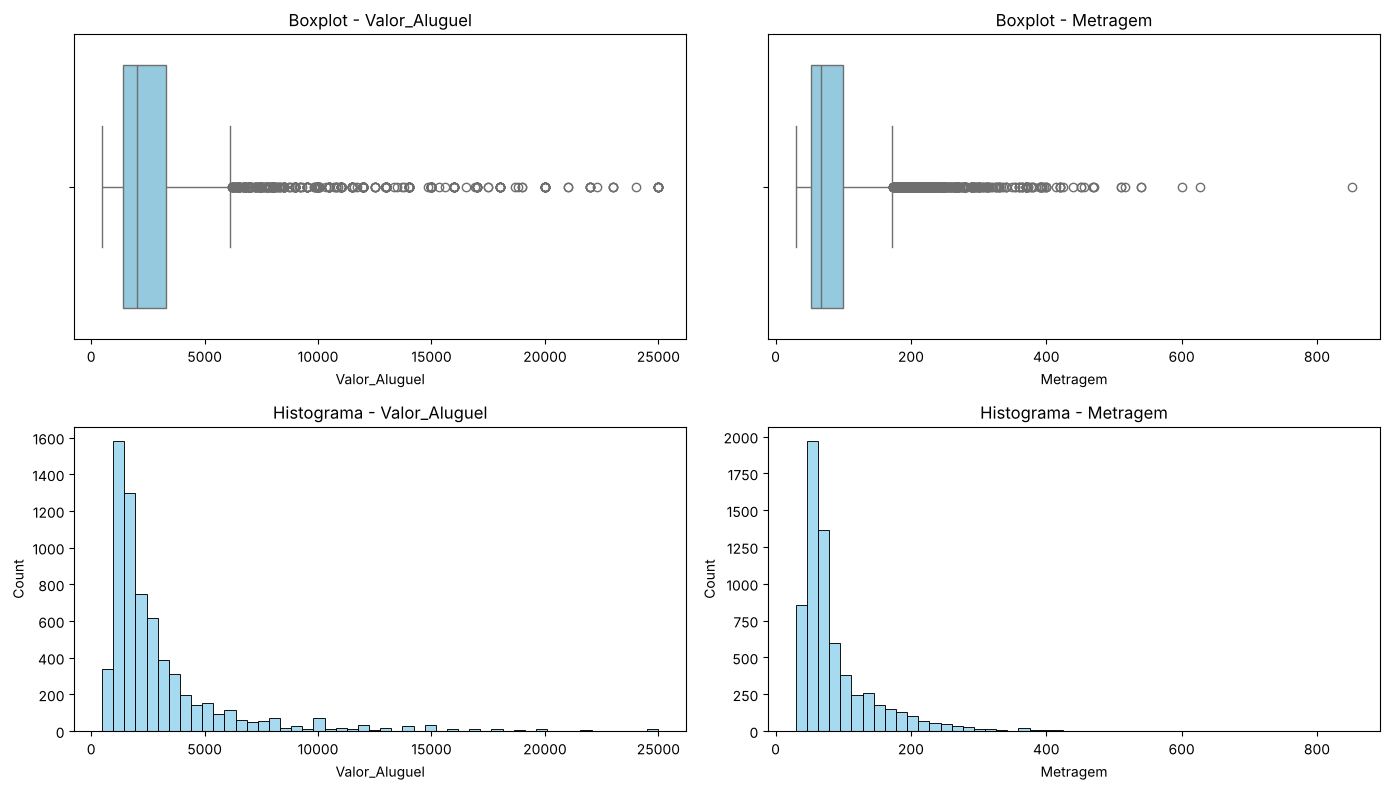

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for i, coluna in enumerate(['Valor_Aluguel', 'Metragem']):
    sns.boxplot(x=df[coluna], ax=axes[0, i], color='skyblue')
    axes[0, i].set_title(f'Boxplot - {coluna}')
    sns.histplot(df[coluna], bins=50, ax=axes[1, i], color='skyblue')
    axes[1, i].set_title(f'Histograma - {coluna}')
plt.tight_layout()
plt.show()

Os histogramas mostram uma concentração forte nos valores baixos e uma cauda longa à direita. No boxplot, aparece uma grande quantidade de pontos além do bigode superior.

**B) Tratamento dos outliers**

Método escolhido: **IQR (intervalo interquartil) com limite de 3 × IQR**, aplicado em `Valor_Aluguel` e `Metragem`.

Justificativa:

* Os valores altos **não são erros de digitação**. São coerentes entre si: os aluguéis mais caros também têm metragem, condomínio e número de vagas altos. São imóveis de alto padrão que existem de verdade.
* Com o limite tradicional de 1,5 × IQR, só o aluguel já teria cerca de 600 imóveis acima de R\$ 6.150, e somando a metragem a perda passaria de 15% da base. Eu estaria descartando um segmento real do mercado.
* Por outro lado, a regressão linear usa mínimos quadrados: o erro de cada ponto é **elevado ao quadrado**, então poucos imóveis muito extremos (R\$ 25.000 ou 800 m²) puxam a reta para si e pioram o ajuste para a grande maioria.
* O limite de 3 × IQR é o critério de Tukey para **outliers extremos**. Ele remove só os casos realmente fora do padrão e mantém os imóveis de valor alto, porém comuns.
* **Não apliquei o IQR nas contagens** (quartos, banheiros, suítes e vagas). São variáveis discretas e concentradas: em `N_banheiros`, por exemplo, Q1 = Q3 = 2, então o IQR é 0 e o método marcaria como outlier todo imóvel que não tem exatamente 2 banheiros, mais de 40% da base. Os casos extremos dessas colunas (10 quartos, 9 vagas) são imóveis grandes e saem junto com a metragem.
* O condomínio também não foi tratado separadamente, porque é muito ligado à metragem e os casos extremos dele saem junto com os outros filtros.

In [12]:
def remover_outliers_iqr(dados, coluna, k=3):
    q1 = dados[coluna].quantile(0.25)
    q3 = dados[coluna].quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - k * iqr
    limite_superior = q3 + k * iqr
    filtro = (dados[coluna] >= limite_inferior) & (dados[coluna] <= limite_superior)
    print(f'{coluna}: limite superior = {limite_superior:.0f} | linhas removidas = {(~filtro).sum()}')
    return dados[filtro]

linhas_antes = len(df)
df = remover_outliers_iqr(df, 'Valor_Aluguel')
df = remover_outliers_iqr(df, 'Metragem')
print(f'Total removido: {linhas_antes - len(df)} linhas ({(linhas_antes - len(df)) / linhas_antes:.1%}) | linhas restantes: {len(df)}')

Valor_Aluguel: limite superior = 9000 | linhas removidas = 323
Metragem: limite superior = 215 | linhas removidas = 147
Total removido: 470 linhas (7.1%) | linhas restantes: 6105


In [13]:
df.describe().round(2)

,Valor_Aluguel,Valor_Condominio,Metragem,N_Quartos,N_banheiros,N_Suites,N_Vagas
count,6105.00,6105.00,6105.00,6105.00,6105.00,6105.00,6105.00
mean,2382.34,685.08,76.79,2.21,1.96,0.88,1.31
std,1523.20,523.69,37.28,0.76,0.81,0.70,0.68
min,480.00,0.00,30.00,1.00,1.00,0.00,0.00
25%,1300.00,389.00,50.00,2.00,1.00,0.00,1.00
50%,1850.00,572.00,65.00,2.00,2.00,1.00,1.00
75%,3000.00,867.00,90.00,3.00,2.00,1.00,2.00
max,9000.00,6059.00,215.00,5.00,7.00,4.00,5.00


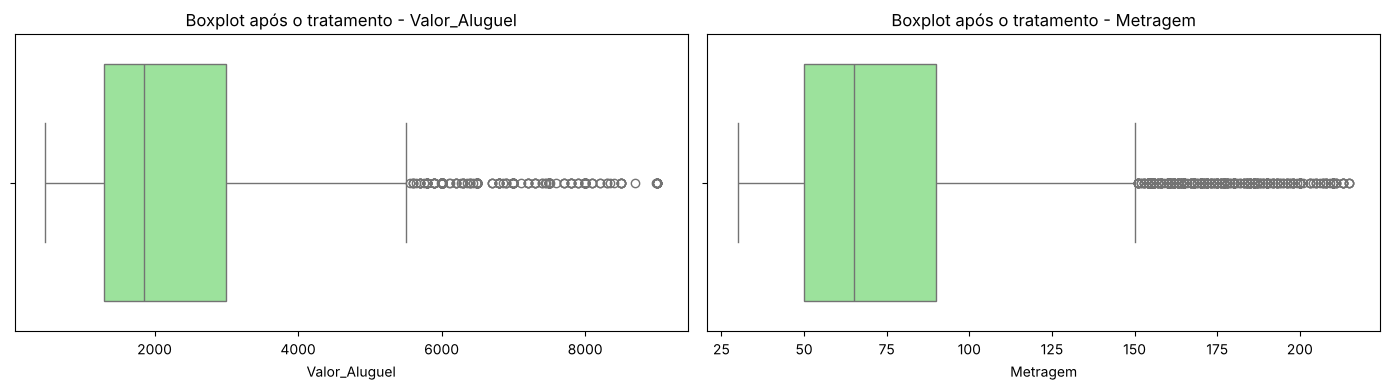

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for i, coluna in enumerate(['Valor_Aluguel', 'Metragem']):
    sns.boxplot(x=df[coluna], ax=axes[i], color='lightgreen')
    axes[i].set_title(f'Boxplot após o tratamento - {coluna}')
plt.tight_layout()
plt.show()

Depois do tratamento, cerca de 7% das linhas saíram e a base ficou com 6.105 imóveis. O aluguel máximo passou de R\$ 25.000 para R\$ 9.000 e a metragem máxima de 852 m² para 215 m². A média do aluguel (≈ R\$ 2.382) ficou mais próxima da mediana (R\$ 1.850) e o desvio padrão caiu pela metade. Ainda aparecem pontos fora do bigode no boxplot, o que é esperado: escolhi manter os imóveis caros que não são extremos.

As outras colunas também ficaram mais realistas, com no máximo 5 quartos e 5 vagas.

**C) Análise bivariada**

**Gráfico 1 - Metragem x Valor do Aluguel**

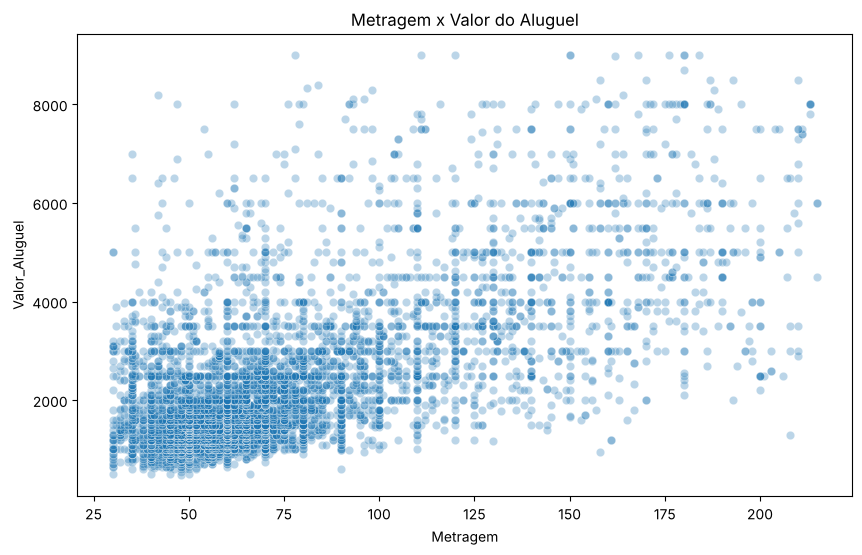

In [15]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='Metragem', y='Valor_Aluguel', alpha=0.3)
plt.title('Metragem x Valor do Aluguel')
plt.show()

**Insight:** existe uma relação positiva clara, já que imóveis maiores tendem a ter aluguel mais alto. A dispersão, porém, cresce conforme a metragem aumenta (o gráfico tem formato de "funil"). Até uns 60 m² os aluguéis ficam mais próximos entre si; acima de 100 m², imóveis do mesmo tamanho podem custar de R\$ 2.000 a R\$ 9.000. Isso indica que a metragem sozinha não explica tudo: outros fatores, que não estão na base (como localização e padrão do prédio), pesam bastante.

**Gráfico 2 - Valor do Condomínio x Valor do Aluguel**

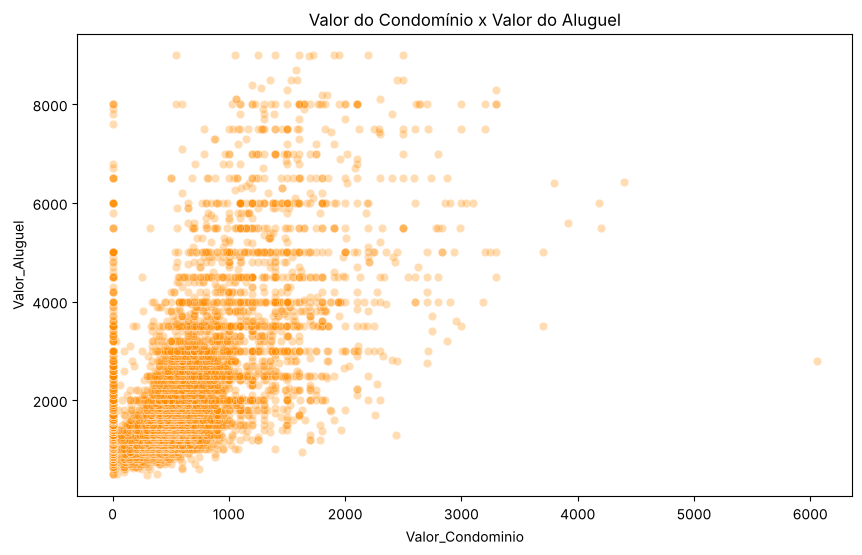

In [16]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='Valor_Condominio', y='Valor_Aluguel', alpha=0.3, color='darkorange')
plt.title('Valor do Condomínio x Valor do Aluguel')
plt.show()

**Insight:** o condomínio também tem relação positiva com o aluguel. Faz sentido, porque um condomínio caro costuma indicar um prédio com mais estrutura (lazer, portaria, segurança), o que também encarece o aluguel. Aparece uma faixa de imóveis com condomínio igual a 0 espalhada por quase todos os valores de aluguel, o que reforça que o zero não segue o padrão dos demais (pode ser imóvel sem condomínio ou valor não informado).

**Gráfico 3 - Número de Quartos x Valor do Aluguel**

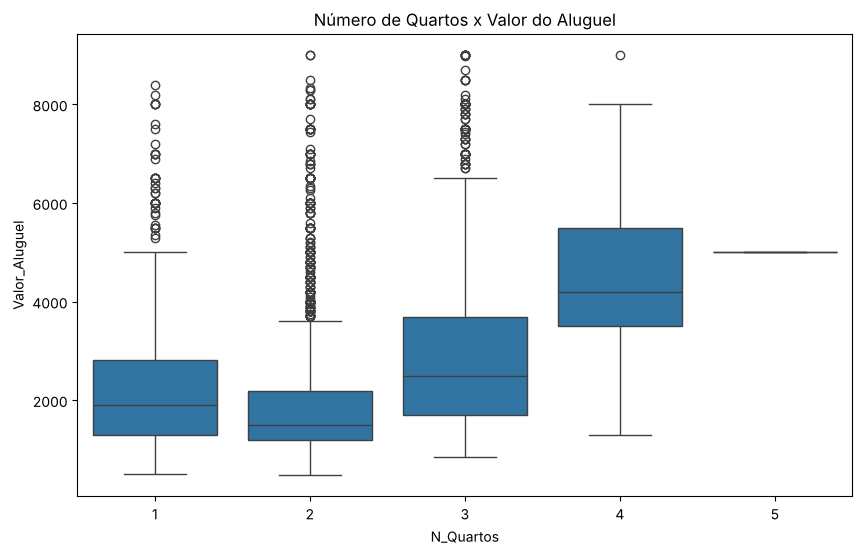

,count,median
N_Quartos,,
1,1048,1900.0
2,2931,1500.0
3,1918,2500.0
4,207,4200.0
5,1,5000.0


In [17]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='N_Quartos', y='Valor_Aluguel')
plt.title('Número de Quartos x Valor do Aluguel')
plt.show()

df.groupby('N_Quartos')['Valor_Aluguel'].agg(['count', 'median'])

**Insight:** a relação **não é linear**. Imóveis de 1 quarto têm mediana de aluguel (R\$ 1.900) **maior** que os de 2 quartos (R\$ 1.500). Uma hipótese é que muitos imóveis de 1 quarto são studios e flats compactos em regiões mais valorizadas. A partir de 3 quartos, o aluguel sobe bastante (mediana de R\$ 2.500 com 3 quartos e de R\$ 4.200 com 4). Só existe 1 imóvel com 5 quartos, então essa caixa não é representativa. Isso explica por que, como veremos na correlação, o número de quartos é a variável mais fraca para prever o aluguel.

**Gráfico 4 - Número de Vagas x Valor do Aluguel**

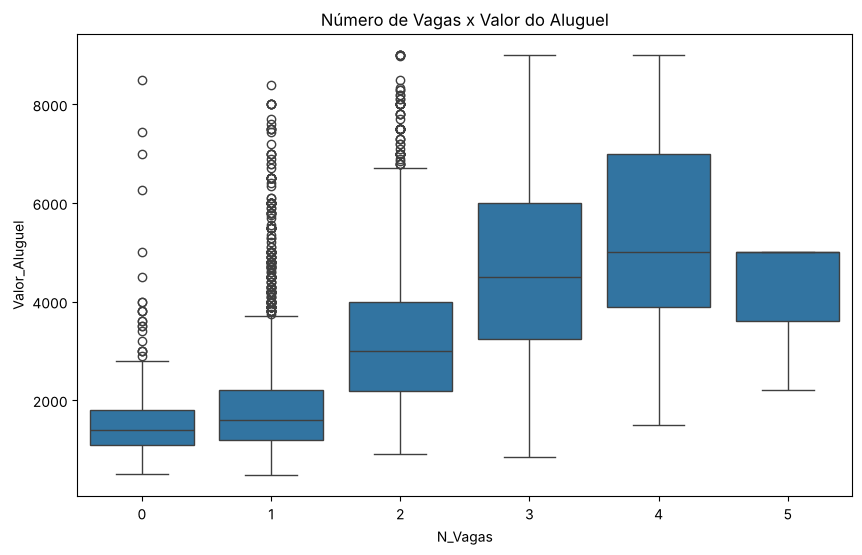

,count,median
N_Vagas,,
0,278,1400.0
1,4080,1600.0
2,1380,3000.0
3,319,4500.0
4,45,5000.0
5,3,5000.0


In [18]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='N_Vagas', y='Valor_Aluguel')
plt.title('Número de Vagas x Valor do Aluguel')
plt.show()

df.groupby('N_Vagas')['Valor_Aluguel'].agg(['count', 'median'])

**Insight:** o número de vagas tem um efeito forte, principalmente na passagem de 1 para 2 vagas: a mediana praticamente dobra (de R\$ 1.600 para R\$ 3.000) e chega a R\$ 4.500 com 3 vagas. Mais vagas costumam indicar imóveis maiores e de padrão mais alto. A maior parte da base (cerca de 2 em cada 3 imóveis) tem só 1 vaga.

# 3 - Realize a terceira etapa de pré processamento dos dados.

A) Comece pela correlação, que sabemos ser uma parte importante para nosso pré processamento e análise. Plote o gráfico ou a tabela e indique as variáveis que te parecem mais "fortes" na correlação para nosso modelo.




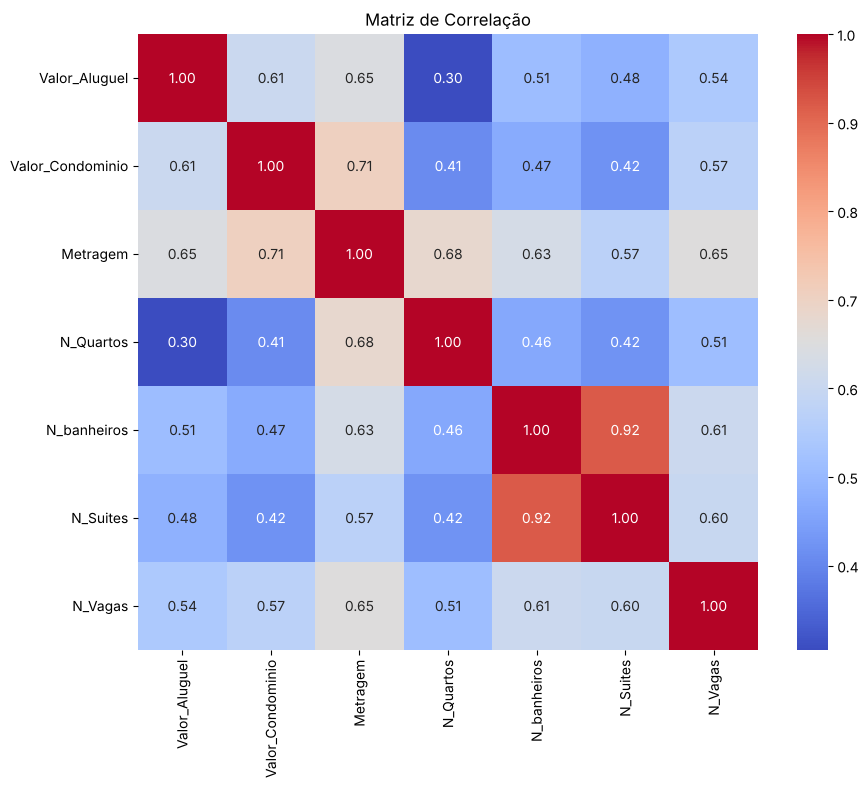

In [19]:
correlacao = df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlacao, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Matriz de Correlação')
plt.show()

In [20]:
correlacao['Valor_Aluguel'].drop('Valor_Aluguel').sort_values(ascending=False)

Metragem            0.646682
Valor_Condominio    0.605194
N_Vagas             0.542587
N_banheiros         0.510553
N_Suites            0.482243
N_Quartos           0.304786
Name: Valor_Aluguel, dtype: float64

**Variáveis mais "fortes":**

* **Metragem (0,65)** é a variável de **maior correlação** com o aluguel, por isso será usada na regressão linear simples.
* **Valor_Condominio (0,61)** vem logo em seguida.
* **N_Vagas (0,54)**, **N_banheiros (0,51)** e **N_Suites (0,48)** têm correlação moderada.
* **N_Quartos (0,31)** é a mais fraca, o que bate com o boxplot, em que o aluguel não cresce de forma linear com os quartos.

Também vale observar a correlação **entre as variáveis independentes**. `N_banheiros` e `N_Suites` têm correlação de 0,92 (carregam quase a mesma informação), e `Metragem` tem correlação de 0,71 com o condomínio e de 0,68 com os quartos. Isso é **multicolinearidade**: na regressão múltipla, essas variáveis vão "dividir" o efeito entre si, então colocar todas não soma tanta informação nova quanto parece.


B) Durante a aula, por nossa base ser pequena e demonstrativa não realizamos a separação de treino e teste, porém para as atividades do dia dia temos que fazer, nesse exercício separe treino e teste.

Lembre-se que primeiro separamos as variaveis dependentes X e depois Y, essa etapa deixarei para vocês abaixo:

In [21]:
X = df.drop('Valor_Aluguel', axis=1) #Separando X - Todas variáveis exceto valor_aluguel
y = df['Valor_Aluguel'] #Separando Y (Apenas variavel valor_aluguel)

Dica: Para separar em treino e teste usamos o train_test_split, como visto nas aulas de pré modelagem.

In [22]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print('Treino:', X_train.shape, '| Teste:', X_test.shape)

Treino: (4884, 6) | Teste: (1221, 6)


Separei **80% para treino e 20% para teste**, uma divisão comum que deixa bastante dado para o modelo aprender e ainda mais de mil imóveis para avaliá-lo. O `random_state=42` garante que a divisão seja sempre a mesma ao rodar o notebook de novo, então os resultados podem ser reproduzidos.

# 3 - Treine um modelo de regressão Linear simples

A) Vamos utilizar apenas X_train e y_train para rodar um modelo de regressão linea simples e para isso usaremos apenas uma váriavel, a váriavel metragem.

In [23]:
X = X_train[['Metragem']]  # Variável independente (características)
y = y_train  # Variável dependente (rótulo)
# se você deu um nome diferente para x train e y train, altere no código.

In [24]:
regressao_simples = LinearRegression()
regressao_simples.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[26.41]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Metragem']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,359.4
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


B) Plote o intercept_ e coef_ e monte de forma extensa a equação da reta.

In [25]:
print('Intercepto (coeficiente linear):', regressao_simples.intercept_)
print('Coeficiente angular (Metragem):', regressao_simples.coef_)

Intercepto (coeficiente linear): 359.38694721456045
Coeficiente angular (Metragem): [26.40674604]


Nossa equação seria: **Valor_Aluguel = 26,41 × Metragem + 359,39**

Ou seja, **cada m² a mais aumenta o aluguel em cerca de R\$ 26,41**. O intercepto de R\$ 359,39 seria o aluguel de um imóvel com 0 m², o que não tem significado prático (o menor imóvel da base tem 30 m²). Ele só serve para posicionar a reta. Exemplo: para um apartamento de 70 m², o modelo prevê 26,41 × 70 + 359,39 ≈ R\$ 2.208.

c) Calcule o R quadrado para o modelo de treinamento. Não esqueça de avaliar e trazer em formato de insight se esse resultado te parece bom ou não.

In [26]:
r2_treino_simples = regressao_simples.score(X, y)
print('R² no treino (regressão simples):', round(r2_treino_simples, 4))

R² no treino (regressão simples): 0.414


**Insight:** o R² de treino é **0,41**, ou seja, a metragem sozinha explica cerca de **41% da variação** do valor do aluguel. Para uma única variável é um resultado razoável e mostra que o tamanho do imóvel importa bastante. Mesmo assim, **não é um bom modelo para prever preços com precisão**: quase 60% da variação fica sem explicação. Isso era esperado, porque o aluguel depende de muitos outros fatores, como localização, estado de conservação, andar, lazer do prédio e o próprio condomínio.

D) Plote o gráfico da reta de regressão encontrada e traga insights acerca da dispersão dos pontos e ajuste da reta.

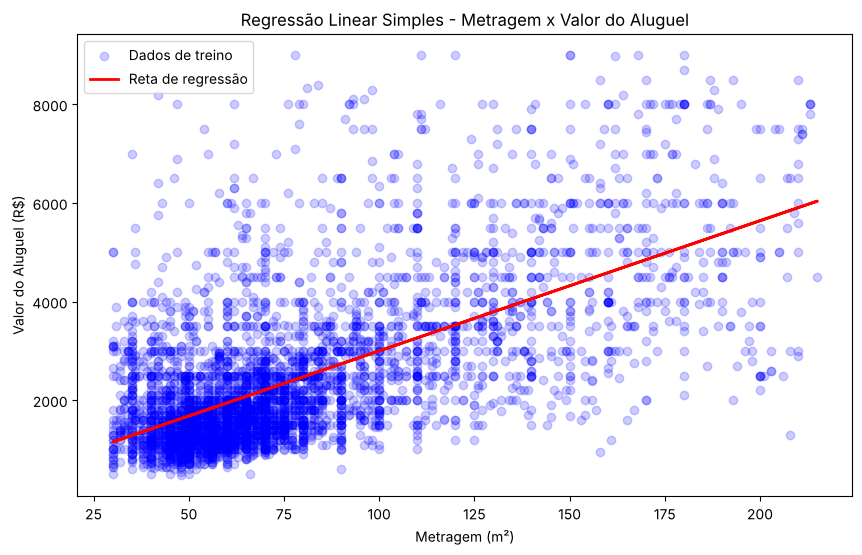

In [27]:
plt.figure(figsize=(10, 6))
plt.scatter(X, y, color='blue', alpha=0.2, label='Dados de treino')
plt.plot(X, regressao_simples.predict(X), color='red', linewidth=2, label='Reta de regressão')
plt.xlabel('Metragem (m²)')
plt.ylabel('Valor do Aluguel (R$)')
plt.title('Regressão Linear Simples - Metragem x Valor do Aluguel')
plt.legend()
plt.show()

**Insight:** a reta segue a tendência geral (sobe com a metragem), mas os pontos estão **bem espalhados ao redor dela**, o que explica o R² de 0,41. Além disso:

* a dispersão **aumenta com a metragem** (formato de funil), então o erro do modelo é menor para imóveis pequenos e bem maior para imóveis grandes;
* para uma mesma metragem existem aluguéis muito diferentes (por exemplo, imóveis de 100 m² entre R\$ 1.500 e R\$ 8.000), uma diferença que a metragem não tem como explicar;
* muitos pontos ficam bem acima da reta nas metragens médias e grandes. São imóveis mais caros do que o tamanho sugere e que o modelo subestima.

E) Para finalizar vamos aplicar o modelo a base de teste. Essa etapa é nova, então agora vocês avaliaram como o modelo treinado se saiu com a base de testes.
Para isso altere no código abaixo o nome do seu modelo de regressão:

In [28]:
X_test = X_test[['Metragem']]  # Variável independente (características)
y_test = y_test  # Variável dependente (rótulo)

In [29]:
# Usando o modelo treinado para fazer previsões sobre os dados de teste
previsoes = regressao_simples.predict(X_test)

# Avaliando o desempenho do modelo usando métricas como o R²
r2 = regressao_simples.score(X_test, y_test)

print("Coeficiente de Determinação (R²) nos Dados de Teste:", r2)

Coeficiente de Determinação (R²) nos Dados de Teste: 0.4350526351066787


Se o valor do coeficiente de determinação (R²) para os dados de treinamento for melhor (ou seja, mais próximo de 1) do que o R² para os dados de teste, isso sugere que o modelo está superajustado aos dados de treinamento. Isso significa que o modelo pode estar se ajustando muito bem aos padrões específicos nos dados de treinamento, mas pode não generalizar bem para novos dados que não foram vistos durante o treinamento.

Por outro lado, se o R² para os dados de teste for melhor do que o R² para os dados de treinamento, isso pode ser indicativo de que o modelo está subajustado. Isso significa que o modelo não está se ajustando adequadamente aos padrões nos dados de treinamento e não está capturando a relação entre as variáveis independentes e dependentes de forma eficaz.

Idealmente, gostaríamos que o valor do R² fosse consistente entre os dados de treinamento e teste, indicando que o modelo é capaz de generalizar bem para novos dados. Se houver uma grande diferença entre os valores de R² para os dados de treinamento e teste, isso sugere que o modelo pode precisar de ajustes para melhorar sua capacidade de generalização.

F) Avalie com suas palavras o valor do r quadrado encontrado no treino e no teste.

| Regressão simples (Metragem) | R² |
|---|---|
| Treino | 0,414 |
| Teste | 0,435 |

Os dois valores são **muito próximos** (diferença de cerca de 0,02). Isso indica que **não há overfitting**: o modelo teve o mesmo desempenho em dados que nunca viu e generaliza bem. O R² de teste ficou um pouco acima do de treino, mas a diferença é pequena demais para concluir algo. É uma variação normal causada pela escolha aleatória de quais imóveis foram para o teste.

O problema desse modelo não é a generalização, e sim o **nível baixo do R² nos dois casos**: ele explica só cerca de 41 a 44% do aluguel. Isso mostra que o modelo é **simples demais** (um sinal de subajuste) porque usa uma única variável. O próximo passo natural é incluir mais informações, que é o que a regressão múltipla faz.

# 4 - Aplicação do modelo de regressão linear multipla!

A) Vamos refazer os passos anteriores porém para regressão multipla, com todas variáveis dependentes. Comece separando a base treino e teste, dessa vez com todas variáveis para X.

Aqui é só refazer os passos do exercicio 3 porém ao invés de trazer para X apenas metragem, você deve trazer todas colunas (exceto a valor do aluguel).

In [30]:
X = df.drop('Valor_Aluguel', axis=1)  # Todas as variáveis independentes
y = df['Valor_Aluguel']

# Mesmo test_size e random_state: os imóveis de treino e teste são os mesmos do modelo simples,
# então a comparação entre os dois modelos é justa
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print('Treino:', X_train.shape, '| Teste:', X_test.shape)

Treino: (4884, 6) | Teste: (1221, 6)


B) Faça o modelo de regressão linear multipla aplicado só a base de treino.

In [31]:
regressao_multipla = LinearRegression()
regressao_multipla.fit(X_train, y_train)

print('Intercepto:', regressao_multipla.intercept_)
pd.Series(regressao_multipla.coef_, index=X_train.columns).round(2)

Intercepto: 723.2937711839636


Valor_Condominio      0.63
Metragem             19.87
N_Quartos          -527.94
N_banheiros         160.24
N_Suites            137.36
N_Vagas             334.53
dtype: float64

C) Traga o valor do R quadrado e avalie o valor encontrado.

In [32]:
r2_treino_multipla = regressao_multipla.score(X_train, y_train)
print('R² no treino (regressão múltipla):', round(r2_treino_multipla, 4))

R² no treino (regressão múltipla): 0.5189


**Avaliação:** o R² de treino é **0,52**, ou seja, as seis variáveis juntas explicam cerca de **52% da variação** do aluguel, contra 41% da regressão simples. É uma melhora relevante, mas o modelo ainda deixa quase metade da variação sem explicação.

Os coeficientes mostram o efeito de cada variável **mantendo as outras constantes**:

* cada vaga a mais soma cerca de R\$ 335 e cada m² a mais cerca de R\$ 20;
* banheiros e suítes somam entre R\$ 140 e R\$ 160 cada;
* **N_Quartos tem coeficiente negativo (≈ -R\$ 528)**. Parece estranho, mas a interpretação é: para uma **mesma metragem**, um imóvel com mais quartos tem cômodos menores, o que costuma indicar um padrão mais simples. Também é um efeito da multicolinearidade entre quartos e metragem, como vimos na correlação. Por isso os coeficientes individuais devem ser lidos com cuidado.

D) Para finalizar aplique o modelo a base de teste e traga o r quadrado de teste.
Dica: Você pode usar os códigos do exercício anterior.

In [33]:
# Usando o modelo treinado para fazer previsões sobre os dados de teste
previsoes_multipla = regressao_multipla.predict(X_test)

# Avaliando o desempenho do modelo usando o R²
r2_teste_multipla = regressao_multipla.score(X_test, y_test)

print("Coeficiente de Determinação (R²) nos Dados de Teste:", r2_teste_multipla)

Coeficiente de Determinação (R²) nos Dados de Teste: 0.507604900581585


E) Compare os r quadrados encontrados pela regressão linear e pela regressão múltipla. Qual modelo te parece melhor? Por qual motivo acredita que isso ocorreu?

| Modelo | R² treino | R² teste |
|---|---|---|
| Regressão linear simples (Metragem) | 0,414 | 0,435 |
| Regressão linear múltipla (6 variáveis) | 0,519 | 0,508 |

**O modelo de regressão múltipla é o melhor.** Ele explica cerca de 51% da variação do aluguel nos dados de teste, contra 44% da regressão simples, um ganho de aproximadamente 7 pontos percentuais em dados que o modelo nunca viu.

**Por que isso aconteceu?**

* O aluguel não depende só do tamanho do imóvel. Condomínio, vagas, banheiros e suítes trazem informações sobre o **padrão do imóvel e do prédio** que a metragem sozinha não captura. Dois imóveis de 80 m² podem ter preços bem diferentes se um tiver 2 vagas e condomínio alto e o outro não.
* O ganho foi menor do que se poderia esperar ao passar de 1 para 6 variáveis por causa da **multicolinearidade**. Várias variáveis estão bastante correlacionadas com a metragem e entre si (banheiros e suítes: 0,92), então parte da informação que elas trazem já estava contida na metragem.
* **Também não há overfitting na regressão múltipla**: o R² de treino (0,519) e o de teste (0,508) são praticamente iguais, então o modelo generaliza bem.

**Conclusão:** para quem quer saber se um apartamento cabe no orçamento, o modelo múltiplo dá uma estimativa de referência melhor, mas ainda com uma margem de erro considerável. O que mais falta na base é a **localização** (bairro ou região), que costuma ser o fator que mais pesa no preço de um aluguel. Incluir essa variável seria o próximo passo para melhorar o modelo.

# 5 - Melhorias no modelo

Esta seção complementa a análise com as melhorias sugeridas na correção do exercício: métricas de erro em reais, análise dos resíduos, tratamento da multicolinearidade e padronização das variáveis. A sugestão de incluir a localização é discutida no fim, porque a base não tem essa informação.

## 5.1 Métricas de erro em reais (MAE, MSE e RMSE)

O R² mostra quanto da variação do aluguel o modelo explica, mas não mostra de quanto é o erro em reais. Para isso, usei três métricas:

* **MAE** (erro absoluto médio): em média, quanto a previsão erra, em R\$.
* **MSE** (erro quadrático médio): média dos erros ao quadrado. Penaliza mais os erros grandes, mas fica em R\$², o que dificulta a leitura.
* **RMSE** (raiz do MSE): volta para a unidade em reais e continua dando mais peso aos erros grandes.

In [34]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def avaliar(nome, y_real, y_previsto):
    mse = mean_squared_error(y_real, y_previsto)
    return {'Modelo': nome,
            'R²': r2_score(y_real, y_previsto),
            'MAE (R$)': mean_absolute_error(y_real, y_previsto),
            'MSE (R$²)': mse,
            'RMSE (R$)': mse ** 0.5}

# Os dois splits usaram o mesmo random_state, então y_test tem os mesmos imóveis para os dois modelos
previsoes_simples = regressao_simples.predict(X_test[['Metragem']])

print('Aluguel médio na base de teste: R$', round(y_test.mean(), 2))
pd.DataFrame([
    avaliar('Regressão simples', y_test, previsoes_simples),
    avaliar('Regressão múltipla', y_test, previsoes_multipla),
]).set_index('Modelo').round(3)

Aluguel médio na base de teste: R$ 2371.71


,R²,MAE (R$),MSE (R$²),RMSE (R$)
Modelo,,,,
Regressão simples,0.435,811.664,1310982.508,1144.981
Regressão múltipla,0.508,751.613,1142622.131,1068.935


**Insight:** a regressão múltipla também erra menos em reais. O MAE cai de cerca de R\$ 812 para R\$ 752 e o RMSE de R\$ 1.145 para R\$ 1.069.

O RMSE é maior que o MAE porque eleva os erros ao quadrado antes de tirar a média, o que dá mais peso aos erros grandes. Os poucos imóveis em que o modelo erra muito puxam esse número para cima.

Na prática, um erro típico entre R\$ 750 e R\$ 1.070 é grande quando o aluguel médio da base de teste é de cerca de R\$ 2.370. A previsão serve como referência para saber se um imóvel está dentro do orçamento, mas ainda não substitui uma avaliação do imóvel.

## 5.2 Análise dos resíduos

O resíduo é a diferença entre o valor real e o previsto (`real - previsto`). Em um bom modelo linear, os resíduos se espalham de forma aleatória em torno de zero, sem formar padrões. A análise abaixo usa os resíduos da regressão múltipla na base de teste.

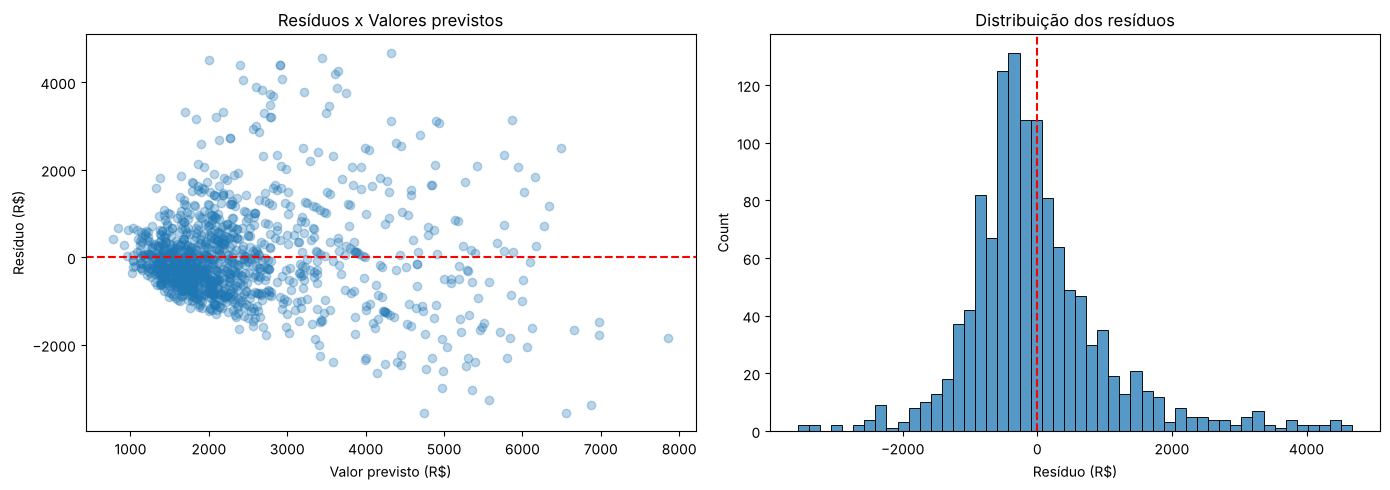

Média dos resíduos: -17.89


In [35]:
residuos = y_test - previsoes_multipla

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(previsoes_multipla, residuos, alpha=0.3)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel('Valor previsto (R$)')
axes[0].set_ylabel('Resíduo (R$)')
axes[0].set_title('Resíduos x Valores previstos')
sns.histplot(residuos, bins=50, ax=axes[1])
axes[1].axvline(0, color='red', linestyle='--')
axes[1].set_xlabel('Resíduo (R$)')
axes[1].set_title('Distribuição dos resíduos')
plt.tight_layout()
plt.show()

print('Média dos resíduos:', round(residuos.mean(), 2))

In [36]:
# Média e desvio padrão dos resíduos por faixa de valor previsto
faixas = pd.cut(previsoes_multipla, bins=[0, 1500, 2500, 3500, 5000, 10000])
residuos.groupby(faixas, observed=True).agg(['count', 'mean', 'std']).round(0)

,count,mean,std
"(0, 1500]",184,6.0,432.0
"(1500, 2500]",673,-77.0,811.0
"(2500, 3500]",190,254.0,1426.0
"(3500, 5000]",117,113.0,1763.0
"(5000, 10000]",57,-569.0,1573.0


**Insight:** a média dos resíduos é praticamente zero (cerca de -R\$ 18), então o modelo não erra sistematicamente para cima nem para baixo. Os resíduos, porém, não são totalmente aleatórios:

* **Formato de funil (heterocedasticidade):** o espalhamento cresce com o valor previsto. Para previsões até R\$ 1.500, o desvio padrão dos resíduos é de cerca de R\$ 430. Acima de R\$ 2.500, passa de R\$ 1.400. O modelo é bem mais preciso para imóveis baratos do que para os caros.
* **Assimetria:** o histograma tem uma cauda longa à direita, com resíduos positivos grandes. São imóveis que custam bem mais do que o modelo prevê, provavelmente por fatores que não estão na base, como localização e padrão do prédio.
* **Sinal de não linearidade:** entre R\$ 2.500 e R\$ 5.000 de previsão, o resíduo médio é positivo (o modelo subestima). Acima de R\$ 5.000, é negativo, cerca de -R\$ 570 (o modelo superestima), embora essa faixa tenha poucos imóveis (57). Uma reta não acompanha perfeitamente a relação.

Dois caminhos para corrigir esses padrões: usar o logaritmo do aluguel como variável alvo (algo comum com preços, porque reduz a assimetria e o funil) e incluir variáveis de localização.

## 5.3 Multicolinearidade entre banheiros e suítes

Na matriz de correlação, `N_banheiros` e `N_Suites` têm correlação de 0,92. Quando duas variáveis carregam quase a mesma informação, a regressão não consegue separar o efeito de cada uma, e os coeficientes ficam instáveis: mudam bastante com pequenas mudanças nos dados.

Para medir isso, usei o **VIF** (Variance Inflation Factor). Para cada variável, ajusto uma regressão dela contra as outras variáveis independentes e calculo VIF = 1 / (1 - R²). Um VIF acima de 5 costuma indicar multicolinearidade preocupante.

In [37]:
def calcular_vif(X):
    vif = {}
    for coluna in X.columns:
        outras = X.drop(columns=coluna)
        r2 = LinearRegression().fit(outras, X[coluna]).score(outras, X[coluna])
        vif[coluna] = 1 / (1 - r2)
    return pd.Series(vif, name='VIF').round(2)

calcular_vif(X_train)

Valor_Condominio    2.11
Metragem            3.65
N_Quartos           1.91
N_banheiros         6.95
N_Suites            6.41
N_Vagas             2.10
Name: VIF, dtype: float64

`N_banheiros` (6,95) e `N_Suites` (6,41) passam do limite de 5. As outras variáveis ficam entre 1,9 e 3,7, o que é aceitável.

Por isso, removi uma das duas. A escolhida foi **N_Suites**, que tem a menor correlação com o aluguel (0,48, contra 0,51 de banheiros). Decidi pela correlação, e não pelo resultado no teste, para não usar a base de teste na construção do modelo.

In [38]:
X_train_sem_suites = X_train.drop(columns='N_Suites')
X_test_sem_suites = X_test.drop(columns='N_Suites')

calcular_vif(X_train_sem_suites)

Valor_Condominio    2.10
Metragem            3.65
N_Quartos           1.90
N_banheiros         1.83
N_Vagas             2.04
Name: VIF, dtype: float64

In [39]:
regressao_sem_suites = LinearRegression()
regressao_sem_suites.fit(X_train_sem_suites, y_train)
previsoes_sem_suites = regressao_sem_suites.predict(X_test_sem_suites)

print('R² treino:', round(regressao_sem_suites.score(X_train_sem_suites, y_train), 4))
print('R² teste:', round(regressao_sem_suites.score(X_test_sem_suites, y_test), 4))
pd.Series(regressao_sem_suites.coef_, index=X_train_sem_suites.columns).round(2)

R² treino: 0.5183
R² teste: 0.5065


Valor_Condominio      0.62
Metragem             19.82
N_Quartos          -529.44
N_banheiros         265.58
N_Vagas             348.24
dtype: float64

Sem `N_Suites`, todos os VIFs ficam abaixo de 4, e o de banheiros cai de 6,95 para 1,83. O desempenho praticamente não muda: o R² de teste vai de 0,508 para 0,506, o que mostra que a variável removida quase não trazia informação nova.

Em compensação, a interpretação fica mais estável:

* o coeficiente de banheiros passou de cerca de R\$ 160 para R\$ 266, porque agora concentra o efeito que antes era dividido com as suítes;
* o erro padrão de um coeficiente cresce com a raiz do VIF, então a incerteza do coeficiente de banheiros cai mais ou menos pela metade (√6,95 ≈ 2,6 contra √1,83 ≈ 1,4).

Outra alternativa seria manter as duas variáveis e usar regularização (Ridge ou Lasso), que penaliza coeficientes grandes e reduz essa instabilidade. Como a remoção resolveu o problema sem perder desempenho, preferi o modelo mais simples.

## 5.4 Padronização das variáveis para comparar os coeficientes

Os coeficientes da regressão estão em unidades diferentes (reais por m², reais por vaga, reais por real de condomínio), por isso não dá para compará-los diretamente. O coeficiente do condomínio (0,62), por exemplo, parece pequeno só porque o condomínio é medido em reais.

Com a **padronização** (`StandardScaler`), cada variável passa a ter média 0 e desvio padrão 1. O coeficiente passa a indicar quanto o aluguel muda quando a variável aumenta **um desvio padrão**. O scaler é ajustado só na base de treino, para não vazar informação da base de teste.

In [40]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_padronizado = scaler.fit_transform(X_train_sem_suites)
X_test_padronizado = scaler.transform(X_test_sem_suites)

regressao_padronizada = LinearRegression()
regressao_padronizada.fit(X_train_padronizado, y_train)
print('R² teste (padronizado):', round(regressao_padronizada.score(X_test_padronizado, y_test), 4))

pd.DataFrame({
    'Desvio padrão da variável': scaler.scale_,
    'Coeficiente padronizado (R$)': regressao_padronizada.coef_,
}, index=X_train_sem_suites.columns).sort_values('Coeficiente padronizado (R$)', key=abs, ascending=False).round(2)

R² teste (padronizado): 0.5065


,Desvio padrão da variável,Coeficiente padronizado (R$)
Metragem,37.11,735.42
N_Quartos,0.76,-402.17
Valor_Condominio,523.57,326.63
N_Vagas,0.67,234.59
N_banheiros,0.81,214.60


O R² continua igual (0,5065), como esperado: a padronização só muda a escala das variáveis, não a qualidade do ajuste. Agora os coeficientes podem ser comparados entre si:

1. **Metragem** é a variável mais importante: cerca de 37 m² a mais (um desvio padrão) aumentam o aluguel em aproximadamente R\$ 735.
2. **N_Quartos** vem em segundo lugar, com efeito negativo (cerca de -R\$ 402): para o mesmo tamanho, mais quartos significam cômodos menores.
3. **Valor_Condominio** (cerca de R\$ 327), **N_Vagas** (R\$ 235) e **N_banheiros** (R\$ 215) vêm depois, com pesos parecidos.

Sem a padronização, o condomínio parecia irrelevante (coeficiente de 0,62), mas ele é a terceira variável mais importante do modelo.

## 5.5 Variáveis de localização (One-Hot Encoding)

A localização costuma ser o fator que mais pesa no preço de um imóvel e é a principal candidata a explicar os quase 50% de variação que o modelo ainda deixa de fora. A base usada aqui **não tem nenhuma coluna de localização**, então não foi possível testar essa melhoria.

Com uma coluna categórica como `Bairro`, o caminho seria transformá-la em variáveis numéricas com One-Hot Encoding, criando uma coluna de 0 ou 1 para cada bairro:

```python
df = pd.get_dummies(df, columns=['Bairro'], drop_first=True)
```

O `drop_first=True` remove uma das colunas para evitar multicolinearidade perfeita (a chamada armadilha das variáveis dummy): se o imóvel não está em nenhum dos outros bairros, ele está necessariamente no bairro que ficou de fora. Conseguir uma base com o bairro ou a região de cada imóvel seria o próximo passo para melhorar o modelo.

## Resumo das melhorias

In [41]:
pd.DataFrame([
    avaliar('Regressão simples', y_test, previsoes_simples),
    avaliar('Regressão múltipla', y_test, previsoes_multipla),
    avaliar('Regressão múltipla sem N_Suites', y_test, previsoes_sem_suites),
]).set_index('Modelo').round(3)

,R²,MAE (R$),MSE (R$²),RMSE (R$)
Modelo,,,,
Regressão simples,0.435,811.664,1310982.508,1144.981
Regressão múltipla,0.508,751.613,1142622.131,1068.935
Regressão múltipla sem N_Suites,0.506,752.086,1145217.768,1070.148


O modelo final escolhido é a **regressão múltipla sem N_Suites**. Ele tem praticamente o mesmo desempenho da múltipla completa (R² de 0,506 e erro médio de cerca de R\$ 750), com uma variável a menos, sem multicolinearidade e com coeficientes mais confiáveis para interpretar.

A análise dos resíduos mostra que o erro cresce nos imóveis mais caros. Os próximos passos são incluir a localização e testar o logaritmo do aluguel como variável alvo.